# Does Corporate Leverage (LEV) Help Explain Stock Returns? Evidence from 1950–2025

**Research question.** Does a long–short portfolio that buys high-leverage stocks and shorts low-leverage stocks earn a positive premium, perform differently in bad economic states, and/or add explanatory power beyond the market, size (SMB), value (HML), and momentum (UMD)? A company with a large debt burden may be more vulnerable when earnings fall, interest rates rise or borrowing becomes difficult. Investors might demand higher expected returns for holding such stocks, but a leverage (LEV) strategy could also overlap with familiar investment characteristics, especially the value factor (HML). We test these possibilities rather than assume that leverage earns a premium.

**Proposed factor:** LEV, an equal-weight high-minus-low debt-to-market-capitalization portfolio. It is an additional candidate factor, not a renamed market, SMB, HML, or UMD factor.

**Economic rationale and falsifiable hypothesis.** High debt increases fixed obligations, refinancing exposure, and sensitivity to falling cash flows. In recessions and negative-market months, investors may dislike this exposure; a positive average high-minus-low premium would be consistent with compensation for bearing bad-state risk. An alternative behavioral account is that investors misprice balance-sheet distress or extrapolate past performance. If high-leverage stocks fall sharply in bad times but LEV earns no reliable average premium, the evidence supports exposure to downside risk without establishing that the risk is rewarded.

**Intended audience:** Quantitative equity managers evaluating potential factor tilts and institutional investors (e.g. pension fund, insurance company) assessing whether a leverage product improves an existing factor portfolio. A factor tilt means deliberately increasing or decreasing a portfolio's exposure to a particular characteristic. For example, if your research found that high-leverage companies consistently earned higher risk-adjusted returns, a quantitative manager might increase the portfolio's exposure to high-leverage stocks. Institutional investors are professionals responsible for deciding how large pools of money are invested and typically evaluate investment strategies rather than selecting every individual stock themselves. If they propose adding a new strategy based on corporate leverage, the factor regressions help answer this question by testing whether LEV adds explanatory power beyond the established factors.

The reader will see how the stock sample is cleaned, how portfolios are formed, whether LEV has a reliable average return, whether it helps explain independent test portfolios beyond existing factors, how sensitive the result is to reasonable construction choices, and what happened in the 2008 and COVID downturns. The final section explains what the evidence can and cannot establish for investors.

## 1. Data Sources, Sample Selection, and Cleaning

There are two input CSVs: CRSP contains `PERMNO` (stock identifier), `MthCalDt` (monthly date), `MthCap` (capitalization in USD thousands), `MthRet` (monthly total return), stock-type flags, and `USIncFlg`. Compustat contains `GVKEY` (company identifier), annual statement date `datadate`, short-term debt `dlc`, long-term debt `dltt` (USD millions), `curcd` (currency), and linking fields. `LPERMNO` identifies the corresponding CRSP stock; `LINKDT` (date the company–stock relationship becomes valid) and `LINKENDDT` (date that relationship stops being valid) specify when that mapping is valid. Link dates are not accounting-publication dates.

**Rules, in execution order:**
1. Parse dates; normalize CRSP observations to calendar month-end. Use the preceding source month to compute the January 2010 lag.
2. Verify repeated `PERMNO`–month rows agree on `MthCap`, `MthRet` and `MthPrevCap`; then keep one detail row. Conflicting economic values raise an error instead of being arbitrarily selected.
3. Calculate `lag_cap` from the previous consecutive calendar month's actual `MthCap`; if that month is absent, leave the lag missing. `MthPrevCap` is used only to check duplicate consistency.
4. Restrict analysis months to January 1950 to December 2025 and eligible CRSP `EQTY`/`COM`/`NS`/`RW` observations, positive current and lagged cap, and observed total return.
5. Keep Compustat annual USD, industrial, consolidated, standard records with at least one debt component and `LC`/`LU`, primary `P`/`C` links. **Accounting availability assumption:** `available_date = datadate + six calendar months`; the month-end of this date must be no later than the return month. This is a conventional lag assumption, not a measured SEC filing date.
6. Use a backward stock-identifier as-of match to the most recently available annual record and require its link validity window to cover the stock month. A latest match failing its link window is dropped, rather than borrowing an older report.

**Universe:** All eligible matched USD-reporting stocks regardless of `USIncFlg`; U.S.-incorporated-only is a separate sensitivity test.

**Return convention:** Monthly stock returns are obtained from CRSP using `MthRet`, which measures total holding-period returns, including dividends and adjustments for corporate actions such as stock splits and distributions. This ensures that portfolio returns reflect the overall economic return earned by investors rather than changes in stock prices alone. The same return measure is used consistently when constructing the high- and low-leverage portfolios and calculating the monthly leverage factor. Monthly factor and portfolio returns are expressed as decimals and displayed means are multiplied by 100 to show percent/month.

In [45]:
import pandas as pd, numpy as np, statsmodels.api as sm
from pathlib import Path
from IPython.display import display
P=Path('.')
raw_c=pd.read_csv(P/'03_Compustat_Annual_and_Link_Source_Data.csv',usecols=['GVKEY','LINKPRIM','LINKTYPE','LPERMNO','LINKDT','LINKENDDT','datadate','indfmt','consol','popsrc','datafmt','conm','curcd','dlc','dltt'],low_memory=False)
raw_r=pd.read_csv(P/'02_CRSP_Monthly_Source_Data.csv',usecols=['PERMNO','SecInfoStartDt','ConditionalType','USIncFlg','SecurityType','SecuritySubType','ShareType','Ticker','MthCalDt','MthCap','MthPrevCap','MthRet','vwretd'],low_memory=False)
assert not {'available_date','lag_cap','signal','debt_millions','q','portfolio_label'}.intersection(set(raw_c.columns)|set(raw_r.columns))
raw_c['datadate']=pd.to_datetime(raw_c.datadate,format='mixed',errors='coerce')
raw_c['LINKDT']=pd.to_datetime(raw_c.LINKDT,format='mixed',errors='coerce')
raw_c['LINKENDDT']=pd.to_datetime(raw_c.LINKENDDT,format='mixed',errors='coerce')
raw_r['date']=pd.to_datetime(raw_r.MthCalDt,errors='coerce').dt.to_period('M').dt.to_timestamp('M')
comp_source_n=len(raw_c); crsp_source_n=len(raw_r)
print('Uploaded source: Compustat rows',comp_source_n,'CRSP rows',crsp_source_n)
print('Actual CRSP range:',raw_r.date.min().date(),'to',raw_r.date.max().date())
assert raw_r.date.max() == pd.Timestamp('2025-12-31'), 'Unexpected combined CRSP endpoint'
# Retain original market capitalization observations before analysis screens, to compute calendar-month lag.
economics=['MthCap','MthRet','MthPrevCap']
conflicts=raw_r.groupby(['PERMNO','date'],dropna=False)[economics].nunique(dropna=False).gt(1).any(axis=1)
assert not conflicts.any(), f'Conflicting CRSP duplicate stock-months: {int(conflicts.sum())}'
r=(raw_r.sort_values(['PERMNO','date','SecInfoStartDt'])
   .drop_duplicates(['PERMNO','date'],keep='last').copy())
crsp_unique_n=len(r); crsp_duplicates_removed=crsp_source_n-crsp_unique_n
r['lag_cap']=r.groupby('PERMNO').MthCap.shift(1)
prior=r.groupby('PERMNO').date.shift(1)
gap=(r.date.dt.year-prior.dt.year)*12+r.date.dt.month-prior.dt.month
r.loc[gap.ne(1),'lag_cap']=np.nan
print('CRSP duplicate detail rows removed:',len(raw_r)-len(r))
r=r[r.date.le('2025-12-31')].copy()
crsp_in_period_n=len(r); crsp_outside_n=crsp_unique_n-crsp_in_period_n
screens=(r.SecurityType.eq('EQTY') & r.SecuritySubType.eq('COM') &
         r.ShareType.eq('NS') & r.ConditionalType.eq('RW') &
         r.MthCap.gt(0) & r.lag_cap.gt(0) & r.MthRet.notna())
print('CRSP screened:',len(r),'→',int(screens.sum()))
crsp_screen_removed=crsp_in_period_n-int(screens.sum()); r=r.loc[screens,['PERMNO','date','MthCap','lag_cap','MthRet','USIncFlg','Ticker','vwretd']].copy(); crsp_screened_n=len(r)
del raw_r
# Annual financial records: standard industrial USD reporting, linked to CRSP.
c=raw_c.loc[(raw_c.curcd.eq('USD')) & raw_c.indfmt.eq('INDL') &
            raw_c.consol.eq('C') & raw_c.popsrc.eq('D') & raw_c.datafmt.eq('STD') &
            raw_c.LINKTYPE.isin(['LC','LU']) & raw_c.LINKPRIM.isin(['P','C']) &
            raw_c.LPERMNO.notna() & raw_c.datadate.notna() &
            raw_c[['dlc','dltt']].notna().any(axis=1)].copy()
comp_screened_n=len(c); comp_screen_removed=comp_source_n-comp_screened_n
c['PERMNO']=c.LPERMNO.astype('int64')
del raw_c
c['available_date']=c.datadate+pd.DateOffset(months=6)
c['available_month']=c.available_date.dt.to_period('M').dt.to_timestamp('M')
c['LINKENDDT']=c.LINKENDDT.fillna(pd.Timestamp('2099-12-31'))
# Preserve distinct link windows, prefer primary P when multiple accounting rows remain.
c['link_priority']=c.LINKPRIM.map({'P':0,'C':1})
c=c.sort_values(['PERMNO','available_month','datadate','link_priority']).drop_duplicates(
    ['PERMNO','datadate','LINKDT','LINKENDDT'],keep='first')
# Memory-efficient as-of match by PERMNO: latest available accounting record per stock-month.
# Link-window validity is verified after the match; a failed match is excluded rather than
# silently borrowing an older report from a different link window.
comp_duplicates_removed=comp_screened_n-len(c)
c=c[['PERMNO','GVKEY','conm','datadate','LINKDT','LINKENDDT','available_date','available_month','dlc','dltt']].copy()
c=c.sort_values(['available_month','PERMNO']).copy()
r=r.sort_values(['date','PERMNO']).copy()
d=pd.merge_asof(r,c,left_on='date',right_on='available_month',by='PERMNO',
                direction='backward',allow_exact_matches=True,suffixes=('','_comp'))
d=d.loc[d.datadate.notna() & (d.LINKDT<=d.date) & (d.date<=d.LINKENDDT)].copy()
d=d.rename(columns={'GVKEY':'gvkey','conm':'company_name'})
d=d.sort_values(['PERMNO','date'])
assert not d.duplicated(['PERMNO','date']).any()
assert (d.available_month<=d.date).all()
print('Matched eligible USD-reporting stock-months:',len(d),'| stocks:',d.PERMNO.nunique(),
      '| observed months:',d.date.nunique())
print('USIncFlg counts:',d.USIncFlg.value_counts(dropna=False).to_dict())
display(d[['date','PERMNO','gvkey','datadate','available_date','lag_cap','MthCap','MthRet','dlc','dltt']].head(10))
# Release source-level temporary tables after the match; the original CSVs remain untouched.
del r,c

Uploaded source: Compustat rows 337915 CRSP rows 5078538
Actual CRSP range: 1950-01-31 to 2025-12-31
CRSP duplicate detail rows removed: 61258
CRSP screened: 5017280 → 3910049
Matched eligible USD-reporting stock-months: 3163800 | stocks: 24145 | observed months: 901
USIncFlg counts: {'Y': 3011616, 'N': 152184}


,date,PERMNO,gvkey,datadate,available_date,lag_cap,MthCap,MthRet,dlc,dltt
1307000,1987-04-30,10000,13007.0,1986-10-31,1987-04-30,973.25,912.42,-0.062500,0.968,0.058
1313367,1987-05-31,10000,13007.0,1986-10-31,1987-04-30,912.42,851.59,-0.066667,0.968,0.058
1282007,1986-12-31,10001,12994.0,1986-06-30,1986-12-30,6937.00,6937.00,0.016154,0.343,2.946
1288186,1987-01-31,10001,12994.0,1986-06-30,1986-12-30,6937.00,6689.25,-0.035714,0.343,2.946
1294415,1987-02-28,10001,12994.0,1986-06-30,1986-12-30,6689.25,6193.75,-0.074074,0.343,2.946
1300690,1987-03-31,10001,12994.0,1986-06-30,1986-12-30,6193.75,6317.63,0.037486,0.343,2.946
1307001,1987-04-30,10001,12994.0,1986-06-30,1986-12-30,6317.63,6069.88,-0.039216,0.343,2.946
1313368,1987-05-31,10001,12994.0,1986-06-30,1986-12-30,6069.88,5636.31,-0.071429,0.343,2.946
1319770,1987-06-30,10001,12994.0,1986-06-30,1986-12-30,5636.31,5822.13,0.052687,0.343,2.946
1326215,1987-07-31,10001,12994.0,1986-06-30,1986-12-30,5822.13,5946.00,0.021277,0.343,2.946


## 2. Winsorization and Portfolio Formation

Compustat reports `dlc` (current debt) and `dltt` (long-term debt) in USD millions. Their sum gives total debt; a missing component is treated as zero only when the other component is reported. The sorting signal divides the most recently available annual debt by previous-month market capitalization, converting CRSP's `lag_cap` from USD thousands to USD millions first. The six-month accounting availability rule has already been applied during matching, so debt is not lagged a second time.

For each calendar month, the notebook separately winsorizes the leverage signal and CRSP monthly total returns at the 1st and 99th percentiles. Winsorization clips extreme values rather than deleting observations. Then, the eligible stocks are ranked by their winsorized debt / lagged market capitalization ratio. It splits that ranking into five approximately equal-count portfolios. Q1 contains the lowest-leverage signals and Q5 the highest. Each portfolio return is the simple average of its member stocks' winsorized CRSP total returns, so every stock receives equal weight regardless of company size. Equal weighting makes this baseline comparison about the typical constituent rather than letting the largest companies dominate; capitalization weighting is examined as a robustness check.

The proposed factor is a long-short portfolio: `LEV = Q5 return − Q1 return`. Long Q5: Take a positive investment position in the highest-leverage stocks. Short Q1: Take a negative investment position in the lowest-leverage stocks. It is described as a theoretical zero-net-investment long–short spread because the two legs have equal notional size; real investors would still face stock-borrow, financing, and trading costs.

In [53]:
d['debt_millions']=d[['dlc','dltt']].fillna(0).sum(axis=1)
d['sorting_debt_millions']=d['debt_millions'] # most recent available accounting report, no second lag
d['signal']=d.sorting_debt_millions/(d.lag_cap/1000)
d=d.loc[np.isfinite(d.signal) & d.MthRet.notna() & d.lag_cap.gt(0)].copy()
def monthly_winsor(s):
    return s.clip(lower=s.quantile(.01),upper=s.quantile(.99))
d['signal_w']=d.groupby('date').signal.transform(monthly_winsor)
d['ret_w']=d.groupby('date').MthRet.transform(monthly_winsor)
d['q']=d.groupby('date').signal_w.transform(
    lambda s:pd.qcut(s.rank(method='first'),5,labels=False)+1).astype(int)
d['portfolio_label']='Q'+d.q.astype(str)
membership_columns=['date','portfolio_label','q','PERMNO','gvkey','company_name','Ticker',
                    'USIncFlg','datadate','available_date','debt_millions','signal','signal_w',
                    'MthRet','ret_w','lag_cap']
membership=d[membership_columns].sort_values(['date','q','PERMNO']).reset_index(drop=True)
print('Created all timing, factor, and membership variables inside notebook.')
print('Membership:',len(membership),'rows')
display(membership)
# The full membership table has been displayed; avoid retaining a second multi-million-row copy.
del membership

Created all timing, factor, and membership variables inside notebook.
Membership: 3163800 rows


,date,portfolio_label,q,PERMNO,gvkey,company_name,Ticker,USIncFlg,datadate,available_date,debt_millions,signal,signal_w,MthRet,ret_w,lag_cap
0,1950-12-31,Q1,1,10516,1722.0,ARCHER-DANIELS-MIDLAND CO,NaN,Y,1950-06-30,1950-12-30,0.000,0.000000,0.000000,0.104885,0.104885,71122.50
1,1950-12-31,Q1,1,15974,1560.0,AMERICAN SHIP BUILDING CO,NaN,Y,1950-06-30,1950-12-30,0.000,0.000000,0.000000,0.020000,0.020000,5550.00
2,1950-12-31,Q1,1,18438,10030.0,STARRETT (L.S.) CO -CL A,NaN,Y,1950-06-30,1950-12-30,0.000,0.000000,0.000000,0.122297,0.122297,5328.75
3,1950-12-31,Q1,1,19430,9126.0,RICHARDSON-VICKS INC,NaN,Y,1950-06-30,1950-12-30,0.000,0.000000,0.000000,-0.010152,-0.010152,34721.25
4,1950-12-31,Q1,1,19860,1295.0,ALLIED MILLS INC,NaN,Y,1950-06-30,1950-12-30,0.000,0.000000,0.000000,0.029213,0.029213,22277.81
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3163795,2025-12-31,Q5,5,93177,176867.0,IT TECH PACKAGING INC,ITP,Y,2024-12-31,2025-06-30,9.602,2.471564,2.471564,-0.044978,-0.044978,3884.99
3163796,2025-12-31,Q5,5,93251,146140.0,PIEDMONT OFFICE REALTY TRUST,PDM,Y,2024-12-31,2025-06-30,2222.346,2.042042,2.042042,-0.045767,-0.045767,1088296.06
3163797,2025-12-31,Q5,5,93264,184256.0,IRONWOOD PHARMACEUTICALS INC,IRWD,Y,2024-12-31,2025-06-30,599.481,1.052873,1.052873,-0.037143,-0.037143,569376.50
3163798,2025-12-31,Q5,5,93368,133764.0,EAGLE BANCORP MONTANA INC,EBMT,Y,2024-12-31,2025-06-30,201.089,1.523365,1.523365,0.198795,0.198795,132003.20


The following summary is generated from the cleaning and winsorization process above. It reports original observations, duplicate detail records removed after checking agreement on economic fields, sample and eligibility exclusions, valid accounting matches, remaining missingness, and values changed by monthly winsorization.

In [56]:
audit=pd.Series({
 'CRSP_source_detail_rows':crsp_source_n,
 'CRSP_duplicate_detail_rows_removed':crsp_duplicates_removed,
 'CRSP_unique_stock_months_after_deduplication':crsp_unique_n,
 'CRSP_rows_outside_analysis_dates_including_history_buffer':crsp_outside_n,
 'CRSP_stock_months_in_full_historical_period_before_screens':crsp_in_period_n,
 'CRSP_stock_months_removed_by_combined_eligibility_screens':crsp_screen_removed,
 'CRSP_stock_months_after_screens':crsp_screened_n,
 'Compustat_source_annual_link_rows':comp_source_n,
 'Compustat_rows_removed_by_annual_link_eligibility_screens':comp_screen_removed,
 'Compustat_eligible_rows_before_link_deduplication':comp_screened_n,
 'Compustat_duplicate_link_rows_removed':comp_duplicates_removed,
 'CRSP_stock_months_without_valid_available_accounting_match':crsp_screened_n-len(d),
 'final_matched_stock_months':len(d),
 'distinct_stocks':d.PERMNO.nunique(),
 'factor_months':d.date.nunique(),
 'duplicate_stock_months_remaining':int(d.duplicated(['PERMNO','date']).sum()),
 'missing_total_returns_remaining':int(d.MthRet.isna().sum()),
 'missing_sort_signal_remaining':int(d.signal_w.isna().sum()),
 'return_values_changed_by_1_99_winsorization':int((d.MthRet-d.ret_w).abs().gt(1e-12).sum()),
 'signal_values_changed_by_1_99_winsorization':int((d.signal-d.signal_w).abs().gt(1e-12).sum())})
display(audit.to_frame('count'))

,count
CRSP_source_detail_rows,5078538
CRSP_duplicate_detail_rows_removed,61258
CRSP_unique_stock_months_after_deduplication,5017280
CRSP_rows_outside_analysis_dates_including_history_buffer,0
CRSP_stock_months_in_full_historical_period_before_screens,5017280
CRSP_stock_months_removed_by_combined_eligibility_screens,1107231
CRSP_stock_months_after_screens,3910049
Compustat_source_annual_link_rows,337915
Compustat_rows_removed_by_annual_link_eligibility_screens,26538
Compustat_eligible_rows_before_link_deduplication,311377


## 3. Baseline Leverage Premium

After calculating one LEV return per eligible month, we take its average across time. That is the historical gross monthly leverage premium. We also test whether the average is distinguishable from zero using an intercept-only regression with six-lag HAC (Newey–West) standard errors. HAC allows for changing return volatility and some dependence across nearby months, which makes an ordinary independent-observations standard error less appropriate. A positive average is a description of this sample; if its p-value is large, we cannot claim a reliably positive premium from these data.

In [58]:
def form_factor(x, k=5, value_weighted=False):
    x=x.copy()
    x['bucket']=x.groupby('date').signal_w.transform(lambda s:pd.qcut(s.rank(method='first'),k,labels=False)+1)
    if value_weighted:
        x['weighted_return']=x.ret_w*x.lag_cap
        totals=x.groupby(['date','bucket'])[['weighted_return','lag_cap']].sum()
        g=(totals.weighted_return/totals.lag_cap).unstack()
    else: g=x.groupby(['date','bucket']).ret_w.mean().unstack()
    out=pd.DataFrame({'low':g[1], 'high':g[k]});out['LEV']=out.high-out.low
    return out

def mean_test(s):
    s=s.dropna();m=sm.OLS(s,np.ones((len(s),1))).fit(cov_type='HAC',cov_kwds={'maxlags':6})
    return {'months':len(s),'mean_monthly_pct':100*s.mean(),'t_HAC':float(m.tvalues.iloc[0]),'p_HAC':float(m.pvalues.iloc[0])}
factor=form_factor(d)
display(pd.DataFrame([mean_test(factor.LEV)],index=['Baseline LEV']).round(4))
print('LEV is high leverage minus low leverage, using winsorized total returns.')

,months,mean_monthly_pct,t_HAC,p_HAC
Baseline LEV,901,0.1948,1.4767,0.1398


LEV is high leverage minus low leverage, using winsorized total returns.


## 4. Size-Sorted Test Portfolios

A factor should help explain returns beyond the two portfolios used to build it. Testing LEV only against its own Q1 and Q5 legs would make the exercise partly circular. Instead, each month we independently sort eligible stocks by their previous month's market capitalization into five roughly equal-count size portfolios, then calculate their equal-weight total returns. These provide five distinct test assets, from smaller to larger stocks. For benchmark regressions, we subtract the corresponding Fama–French risk-free rate (`RF`) from each portfolio's total return because asset-pricing models explain excess returns, not raw returns.

In [69]:
d['size_q']=d.groupby('date').lag_cap.transform(lambda s:pd.qcut(s.rank(method='first'),5,labels=False)+1)
size=d.groupby(['date','size_q']).ret_w.mean().unstack().rename(columns=lambda x:f'Size{x}')
print('Five independent size test portfolios:',size.columns.tolist())

Five independent size test portfolios: ['Size1', 'Size2', 'Size3', 'Size4', 'Size5']


## 5. Benchmark Factors and Return Conventions

File 4 contains the official monthly market excess return (`Mkt_RF`), size (`SMB`), value (`HML`), momentum (`Mom`) and risk-free rate (`RF`) from the supplied Fama–French source archives. Values have been converted from published percentage points to decimals to match CRSP `MthRet`. The market-only CAPM is our simplest benchmark; FF3 adds size and value, and FF3 plus momentum is the most comprehensive benchmark here. For each independent test portfolio we subtract `RF` from its total return, since these regressions explain returns above the risk-free rate. We do not subtract `RF` again from LEV: LEV is already a long-minus-short return spread.

The benchmark and stock-return samples are joined by calendar month, not by row position. The displayed overlap counts make it clear exactly which months enter the comparisons. For historical stress classification we use the CRSP `vwretd` total market-return proxy; this is not the same as the Fama–French excess-market factor, so it is labeled separately.

In [74]:
ff=pd.read_csv(P/'04_Fama_French_Monthly_Factors.csv',parse_dates=['date']).set_index('date')
assert ff.index.is_unique
assert ff[['Mkt_RF','SMB','HML','Mom','RF']].notna().all().all()
print('Benchmark period:',ff.index.min().date(),'to',ff.index.max().date())
display(ff.head(10))

Benchmark period: 1950-01-31 to 2025-12-31


,Mkt_RF,SMB,HML,Mom,RF
date,,,,,
1950-01-31,0.0170,0.0334,0.0015,-0.0227,0.0009
1950-02-28,0.0148,0.0002,-0.0079,0.0138,0.0009
1950-03-31,0.0126,-0.0143,-0.0278,0.0146,0.0010
1950-04-30,0.0394,0.0200,0.0133,0.0027,0.0009
1950-05-31,0.0432,-0.0213,0.0047,0.0029,0.0010
1950-06-30,-0.0596,-0.0241,-0.0079,-0.0158,0.0010
1950-07-31,0.0137,0.0054,0.1369,-0.0052,0.0010
1950-08-31,0.0486,0.0074,-0.0137,0.0320,0.0010
1950-09-30,0.0482,0.0059,-0.0110,-0.0020,0.0010


## 6. Regression Results and Incremental Explanatory Power

For each independent size portfolio, we estimate three before-and-after comparisons: CAPM versus CAPM + LEV; FF3 versus FF3 + LEV; and FF3 + momentum versus the same model + LEV. This holds the benchmark fixed within each pair, so the change in adjusted R² shows how much extra in-sample fit comes from adding LEV while penalizing the extra variable. The LEV coefficient tells us how strongly a test portfolio moves with LEV; its HAC t-statistic and p-value indicate how uncertain that estimate is. More fit does not automatically mean a profitable or independent investment strategy.

**Could LEV mainly be a value tilt?** Both debt-to-market-capitalization and HML's book-to-market characteristic share market equity in the denominator, so lower stock valuations can make a company appear both more leveraged and more value-like. We check the monthly LEV–HML correlation, then regress LEV on HML alone to see how much of its variation value explains. A second factor-spanning regression explains LEV using market, SMB, HML and momentum together. Its intercept (alpha) tests whether an average LEV return remains after those exposures are accounted for. A nonsignificant alpha means we have not established an independent premium; it does not prove LEV and HML are identical. All these comparisons use months where the required official factors and portfolio returns are both available.le available overlapping months benchmark overlap.

In [87]:
joined=size.join(factor[['LEV']]).join(ff,how='inner').dropna()
assert len(joined)>60, 'Insufficient benchmark overlap'
models={'CAPM':['Mkt_RF'],'CAPM + LEV':['Mkt_RF','LEV'],'FF3':['Mkt_RF','SMB','HML'],'FF3 + LEV':['Mkt_RF','SMB','HML','LEV'],'FF3 + Mom':['Mkt_RF','SMB','HML','Mom'],'FF3 + Mom + LEV':['Mkt_RF','SMB','HML','Mom','LEV']}
rows=[]
for asset in size.columns:
    y=joined[asset]-joined.RF
    for model,features in models.items():
        fit=sm.OLS(y,sm.add_constant(joined[features])).fit(cov_type='HAC',cov_kwds={'maxlags':6})
        rows.append({'portfolio':asset,'model':model,'months':len(y),'alpha_monthly_pct':100*fit.params['const'],'alpha_t':fit.tvalues['const'],'LEV_beta':fit.params.get('LEV',np.nan),'LEV_t':fit.tvalues.get('LEV',np.nan),'LEV_p':fit.pvalues.get('LEV',np.nan),'R2':fit.rsquared,'adjusted_R2':fit.rsquared_adj})
reg=pd.DataFrame(rows)
display(reg.round(4))
for base,plus in [('CAPM','CAPM + LEV'),('FF3','FF3 + LEV'),('FF3 + Mom','FF3 + Mom + LEV')]:
    a=reg[reg.model.eq(base)].set_index('portfolio');b=reg[reg.model.eq(plus)].set_index('portfolio')
    print(base,'→ +LEV: mean change in adjusted R²:',round((b.adjusted_R2-a.adjusted_R2).mean(),4),'significant LEV portfolios:',int((b.LEV_p<.05).sum()),'of',len(b))
# Factor-spanning check: specifically quantify overlap with value (HML).
sp=joined[['LEV','Mkt_RF','SMB','HML','Mom']].dropna()
value_corr=sp.LEV.corr(sp.HML)
span_rows=[]
for label,cols in [('HML only',['HML']),('Market + SMB + HML + Mom',['Mkt_RF','SMB','HML','Mom'])]:
    fit=sm.OLS(sp.LEV,sm.add_constant(sp[cols])).fit(cov_type='HAC',cov_kwds={'maxlags':6})
    span_rows.append({'model':label,'months':len(sp),'R2':fit.rsquared,'HML_beta':fit.params['HML'],
                      'HML_p':fit.pvalues['HML'],'alpha_monthly_pct':100*fit.params['const'],'alpha_p':fit.pvalues['const']})
spanning=pd.DataFrame(span_rows)
print('LEV–HML correlation:',round(value_corr,4))
display(spanning.round(4))

,portfolio,model,months,alpha_monthly_pct,alpha_t,LEV_beta,LEV_t,LEV_p,R2,adjusted_R2
0,Size1,CAPM,901,-0.1219,-0.5971,NaN,NaN,NaN,0.4220,0.4213
1,Size1,CAPM + LEV,901,-0.1925,-0.9365,0.3168,2.2103,0.0271,0.4445,0.4432
2,Size1,FF3,901,-0.2060,-1.5503,NaN,NaN,NaN,0.6673,0.6662
3,Size1,FF3 + LEV,901,-0.1695,-1.2205,0.4707,4.8941,0.0000,0.6928,0.6914
4,Size1,FF3 + Mom,901,0.0628,0.3924,NaN,NaN,NaN,0.6953,0.6939
5,Size1,FF3 + Mom + LEV,901,0.0134,0.0820,0.3183,3.5421,0.0004,0.7048,0.7032
6,Size2,CAPM,901,-0.1946,-1.4051,NaN,NaN,NaN,0.6286,0.6282
7,Size2,CAPM + LEV,901,-0.2522,-1.8283,0.2581,2.6474,0.0081,0.6478,0.6470
8,Size2,FF3,901,-0.2953,-4.0307,NaN,NaN,NaN,0.8730,0.8726
9,Size2,FF3 + LEV,901,-0.2729,-3.7492,0.2894,5.4598,0.0000,0.8853,0.8848


CAPM → +LEV: mean change in adjusted R²: 0.0108 significant LEV portfolios: 4 of 5
FF3 → +LEV: mean change in adjusted R²: 0.0083 significant LEV portfolios: 4 of 5
FF3 + Mom → +LEV: mean change in adjusted R²: 0.0028 significant LEV portfolios: 3 of 5
LEV–HML correlation: 0.6942


,model,months,R2,HML_beta,HML_p,alpha_monthly_pct,alpha_p
0,HML only,901,0.4819,0.8207,0.0,-0.0382,0.6994
1,Market + SMB + HML + Mom,901,0.5803,0.7452,0.0,0.1552,0.0607


## 7. Are the Findings Sensitive to How We Construct LEV? Robustness Check

A factor should not look persuasive only because we made one particular sorting choice. We keep the eligible history intact and change one construction decision at a time. **Value weighting** gives larger firms more influence and checks whether the baseline equal-weight result is driven by small stocks. **Terciles rather than quintiles** broaden the high- and low-leverage groups, checking whether the result depends on an especially narrow extreme portfolio. The **US-incorporated-only** version checks whether other USD-reporting companies affect the conclusion. All versions use the same definition of LEV and the same six-lag HAC mean test. These are sensitivity checks, not a search for whichever variation produces the smallest p-value.

In [89]:
# Compare three transparent alternatives, changing one construction assumption at a time.
rob_rows=[]
for name,k,vw,us_only in [('Baseline: equal-weight quintiles',5,False,False),
                          ('Value-weight quintiles',5,True,False),
                          ('Equal-weight terciles',3,False,False),
                          ('US-incorporated only',5,False,True)]:
    # Use a narrow temporary view for the restricted universe rather than copying all source columns.
    panel=d.loc[d.USIncFlg.eq('Y'),['date','signal_w','ret_w','lag_cap']] if us_only else d
    rob_rows.append({'specification':name,**mean_test(form_factor(panel,k,vw).LEV)})
rob=pd.DataFrame(rob_rows)
display(rob.round(4))
print('Main sample:',len(d),'stock-months; US-incorporated subset:',int(d.USIncFlg.eq('Y').sum()))

,specification,months,mean_monthly_pct,t_HAC,p_HAC
0,Baseline: equal-weight quintiles,901,0.1948,1.4767,0.1398
1,Value-weight quintiles,901,0.0469,0.2741,0.7840
2,Equal-weight terciles,901,0.1771,1.5108,0.1308
3,US-incorporated only,901,0.2129,1.6235,0.1045


Main sample: 3163800 stock-months; US-incorporated subset: 3011616


## 8. Leverage Returns During Market Downturns

Debt creates fixed payment obligations, so high-leverage companies may suffer when profits fall, financing tightens or investors become more risk-averse. We therefore compare LEV in **negative market months** and in **severe market declines** (CRSP `vwretd` at or below −5%), rather than defining bad times after seeing LEV's return. We also report two externally dated economic episodes: the **NBER Great Recession (December 2007–June 2009)** and the **NBER COVID recession (February–April 2020)**. To make the most intense market moves visible, we additionally show September 2008–March 2009 and February–March 2020 as short crash windows. The crash windows are descriptive illustrations, not additional independent economic cycles.

The table displays the low-leverage (Q1), high-leverage (Q5) and long–short LEV averages for each condition. For groups containing at least 12 months, a six-lag HAC test asks whether the *within-group* average LEV return differs from zero. A separate stress-indicator regression asks whether the stress average differs from the average in *other* months. A significant within-group mean does not establish a significant difference between groups. Very short event windows, especially the three-month COVID recession and two-month initial crash, are shown descriptively only; there are too few observations for credible standalone HAC inference. Multiple stress definitions are exploratory and no multiple-testing adjustment is applied. Even a negative downturn return cannot by itself distinguish rational compensation for bad-times risk from behavioral mispricing.g.

Observed factor months: 901 | Great Recession months represented: 19


,condition,months,Q1_low_mean_pct,Q5_high_mean_pct,LEV_mean_pct,LEV_HAC_t,LEV_HAC_p
0,Down-market: CRSP vwretd < 0,329,-4.1761,-3.6083,0.5678,1.9666,0.0492
1,Nonnegative CRSP market,572,3.8526,3.8328,-0.0198,-0.1071,0.9147
2,Severe decline: CRSP vwretd <= -5%,77,-10.0051,-9.1219,0.8832,1.0227,0.3064
3,Other than severe decline,824,1.9419,2.0723,0.1304,0.9739,0.3301
4,NBER Great Recession: Dec 2007-Jun 2009,19,-1.0537,-1.5064,-0.4527,-0.3920,0.6951
5,Outside Great Recession,882,0.9634,1.1721,0.2087,1.5933,0.1111
6,Crisis peak: Sep 2008-Mar 2009,7,-5.4343,-8.1016,-2.6672,NaN,NaN
7,Outside crisis peak,894,0.9707,1.1878,0.2172,1.6499,0.0990
8,NBER COVID recession: Feb-Apr 2020,3,-1.3270,-5.7637,-4.4368,NaN,NaN
9,Initial COVID crash: Feb-Mar 2020,2,-11.9048,-21.3566,-9.4518,NaN,NaN


,comparison,stress_months,other_months,LEV_difference_pct,diff_HAC_t,diff_HAC_p
0,Down market vs nonnegative,329,572,0.5875,1.8000,0.0719
1,Severe decline vs other months,77,824,0.7528,1.0663,0.2863
2,Great Recession vs other months,19,882,-0.6615,-0.5706,0.5683
3,Crisis peak vs other months,7,894,-2.8844,NaN,NaN
4,COVID recession vs other months,3,898,-4.6470,NaN,NaN
5,Initial COVID crash vs other months,2,899,-9.6680,NaN,NaN


Blank inference entries indicate fewer than 12 stress/comparison months, not a p-value of zero.


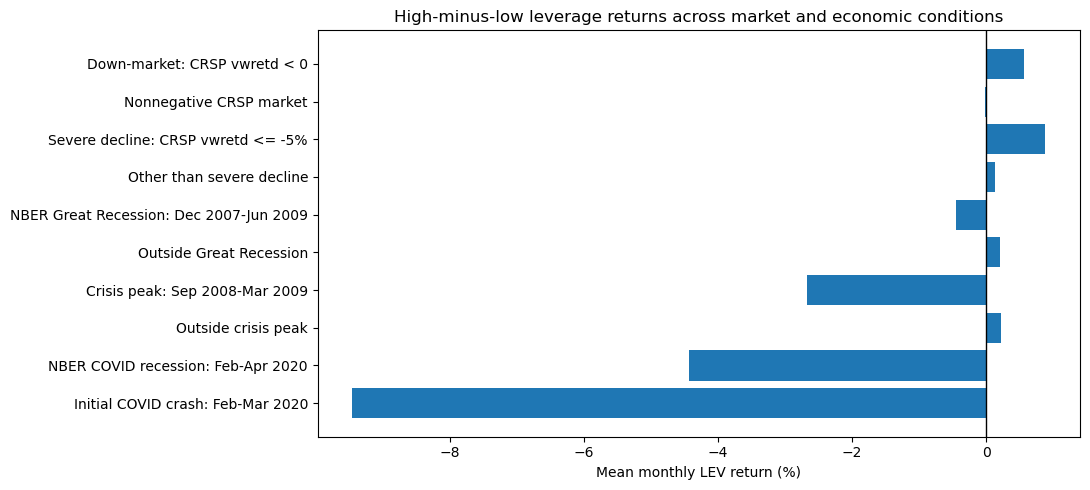

In [92]:
# Merge each month's Q1, Q5 and LEV with the official market factor; align calendar month-end.
market_proxy=d.groupby('date')['vwretd'].median().rename('market_vw_proxy')
stress=factor[['low','high','LEV']].join(market_proxy,how='inner').dropna().sort_index()
stress.index=pd.to_datetime(stress.index).to_period('M').to_timestamp('M')
assert stress.index.is_unique
stress['down_market']=stress.market_vw_proxy.lt(0)
stress['severe_decline']=stress.market_vw_proxy.le(-.05)
stress['great_recession']=stress.index.to_period('M').isin(pd.period_range('2007-12','2009-06',freq='M'))
stress['covid_recession']=stress.index.to_period('M').isin(pd.period_range('2020-02','2020-04',freq='M'))
stress['covid_crash']=stress.index.to_period('M').isin(pd.period_range('2020-02','2020-03',freq='M'))
stress['crisis_peak']=stress.index.to_period('M').isin(pd.period_range('2008-09','2009-03',freq='M'))

conditions=[
 ('Down-market: CRSP vwretd < 0',stress.down_market),
 ('Nonnegative CRSP market',~stress.down_market),
 ('Severe decline: CRSP vwretd <= -5%',stress.severe_decline),
 ('Other than severe decline',~stress.severe_decline),
 ('NBER Great Recession: Dec 2007-Jun 2009',stress.great_recession),
 ('Outside Great Recession',~stress.great_recession),
 ('Crisis peak: Sep 2008-Mar 2009',stress.crisis_peak),
 ('Outside crisis peak',~stress.crisis_peak),
 ('NBER COVID recession: Feb-Apr 2020',stress.covid_recession),
 ('Initial COVID crash: Feb-Mar 2020',stress.covid_crash)]
def conditional_summary(label,mask):
    x=stress.loc[mask,['low','high','LEV']]
    ans={'condition':label,'months':len(x),'Q1_low_mean_pct':100*x.low.mean(),
         'Q5_high_mean_pct':100*x.high.mean(),'LEV_mean_pct':100*x.LEV.mean()}
    if len(x)>=12:
        t=mean_test(x.LEV)
        ans.update(LEV_HAC_t=t['t_HAC'],LEV_HAC_p=t['p_HAC'])
    else:
        ans.update(LEV_HAC_t=np.nan,LEV_HAC_p=np.nan)
    return ans
stress_table=pd.DataFrame([conditional_summary(label,mask) for label,mask in conditions])
print('Observed factor months:',len(stress),'| Great Recession months represented:',int(stress.great_recession.sum()))
display(stress_table.round(4))
diff_rows=[]
for label,mask in [('Down market vs nonnegative',stress.down_market),
                   ('Severe decline vs other months',stress.severe_decline),
                   ('Great Recession vs other months',stress.great_recession),
                   ('Crisis peak vs other months',stress.crisis_peak),
                   ('COVID recession vs other months',stress.covid_recession),
                   ('Initial COVID crash vs other months',stress.covid_crash)]:
    row={'comparison':label,'stress_months':int(mask.sum()),'other_months':int((~mask).sum()),
         'LEV_difference_pct':100*(stress.loc[mask,'LEV'].mean()-stress.loc[~mask,'LEV'].mean())}
    if mask.sum()>=12 and (~mask).sum()>=12:
        fit=sm.OLS(stress.LEV,sm.add_constant(mask.astype(int).rename('stress'))).fit(
            cov_type='HAC',cov_kwds={'maxlags':6})
        row.update(diff_HAC_t=fit.tvalues['stress'],diff_HAC_p=fit.pvalues['stress'])
    else: row.update(diff_HAC_t=np.nan,diff_HAC_p=np.nan)
    diff_rows.append(row)
stress_differences=pd.DataFrame(diff_rows)
display(stress_differences.round(4))
print('Blank inference entries indicate fewer than 12 stress/comparison months, not a p-value of zero.')

# A focused comparison plot; descriptive bars, not confidence intervals.
import matplotlib.pyplot as plt
plot=stress_table
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(plot['condition'],plot['LEV_mean_pct'])
ax.axvline(0,linewidth=1,color='black')
ax.set_xlabel('Mean monthly LEV return (%)')
ax.set_title('High-minus-low leverage returns across market and economic conditions')
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 9. Findings, Economic Explanations, and Investment Implications

The preceding tables are computed directly from the current 1950–2025 inputs. Read the baseline mean together with its HAC p-value: a positive sample average is not proof of a reliably positive premium. Compare the alternative portfolio constructions with the baseline to see whether the direction and statistical conclusion survive different weighting, sorting and universe choices. The independent size-portfolio regressions ask whether LEV adds explanatory information beyond the market, size, value and momentum; an adjusted-R² improvement is **in-sample model fit**, not an investable profit forecast.

The direct LEV–HML correlation and factor-spanning regressions matter because both debt-to-market-capitalization and book-to-market contain market equity in the denominator. Strong co-movement suggests overlap with value, but only the spanning results show how much of LEV's return variation existing factors explain. An insignificant spanning alpha means this study does not establish a distinct premium; it does not prove mathematical identity. Likewise, poor returns in the 2008 or COVID windows are consistent with leverage-related downside exposure, but short historical episodes do not establish a causal mechanism. Both a rational risk explanation (investors require compensation for losses in bad states) and a behavioral explanation (investors misjudge or overreact to leverage) remain possible.

For quantitative managers and institutional allocators, the practical question is whether adding LEV improves an existing portfolio **after** realistic implementation costs. This notebook measures gross historical returns only: executable bid–ask spreads, commissions, stock-borrow availability and fees, financing and margin requirements are not supplied. It also does not claim a separately reserved out-of-sample validation period. Therefore, it should not be read as a recommendation to trade a standalone long–short leverage product merely because one in-sample statistic looks favorable. Under semi-strong market efficiency, public accounting information should not yield an easy abnormal profit after adjustment for risk and costs; Grossman–Stiglitz near-efficiency also allows limited gross opportunities that are consumed by information and implementation costs.

### What the numbers reveal

The dataset contains **3,163,800 stock-month observations**, **24,145 distinct stocks** and **901 monthly LEV returns (December 1950–December 2025)**. The baseline equal-weight LEV averages **+0.1948% per month**, but the HAC t-statistic is **1.4767** and p-value is **0.1398**: the sample does not establish a statistically reliable positive mean at the conventional 5% level. The value-weighted version averages **+0.0469%** (p = 0.7840), the tercile version **+0.1771%** (p = 0.1308), and the US-incorporated-only version **+0.2129%** (p = 0.1045). None establishes a significant standalone premium.

The LEV–HML correlation is **+0.6942**. HML alone explains **48.19%** of LEV's monthly variation (R² = 0.4819), which is substantial value-factor overlap, not proof of identical factors. The full market/size/value/momentum spanning model explains **58.03%** of LEV variation; its estimated monthly alpha is **+0.1552%** with p = **0.0607**, not significant at 5%. Adding LEV increases mean adjusted R² for the independent size test portfolios by **0.0108** over CAPM, **0.0083** over FF3, and **0.0028** over FF3 plus momentum. LEV therefore provides some in-sample explanatory information, but the added fit shrinks as the benchmark becomes more comprehensive.

**The bad-times evidence is mixed rather than uniformly negative.** Across **329 negative CRSP-market months**, LEV averages **+0.5678%** (within-condition HAC p = 0.0492); its difference from nonnegative-market months is **+0.5875 percentage points** but is not significant at 5% (p = 0.0719). In the **77 severe-decline months**, LEV averages **+0.8832%** (p = 0.3064). By contrast, it averages **−0.4527%** during the 19-month Great Recession and **−2.6672%** during the seven-month acute 2008–09 crisis window. The three-month COVID recession average is **−4.4368%**, and the two-month initial COVID crash average is **−9.4518%**. Those short COVID and acute-crisis figures describe particular events, not reliable standalone estimates. The broader negative-market and severe-decline results mean we should **not** claim that LEV systematically loses in every downturn; the pattern depends on which adverse condition is examined.

## 10 | Reproducibility and Study Limitations

Place the five files listed below in the same directory, open `01_Corporate_Leverage_Factor_Study.ipynb`, and select **Kernel → Restart & Run All**. The notebook performs all cleaning, matching, accounting-date alignment, leverage calculations, winsorization, portfolio formation, regressions and sensitivity checks locally without downloading data.

| File | Contents |
|:--|:--|
| `01_Corporate_Leverage_Factor_Study.ipynb` | Complete executable analysis, explanation, results and conclusion |
| `02_CRSP_Monthly_Source_Data.csv` | Original-column monthly stock data and preceding-month source history, without derived analysis variables |
| `03_Compustat_Annual_and_Link_Source_Data.csv` | Original-column annual financial data and company–stock linking information, without derived analysis variables |
| `04_Fama_French_Monthly_Factors.csv` | Monthly market, size, value, momentum and risk-free benchmarks in decimal units |

The sample is limited by the available source extracts, eligible common-stock screens, usable annual debt and valid CRSP–Compustat links. A six-month reporting lag approximates public availability rather than using exact filing dates; lagged market capitalization avoids using current-month valuation to form the portfolio; winsorization and deterministic tie-breaking improve stability and reproducibility but can affect assignments. The long history spans changing reporting and market environments, so estimates need not be constant over time. Crisis comparisons are exploratory, not causal experiments, and statistical significance does not account for multiple comparisons. The analysis excludes actual trading, stock-borrow and financing costs and does not reserve an independent out-of-sample test period. These limitations should accompany the reported results.